In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/tourism_dataset.csv')
df

,Location,Country,Category,Visitors,Rating,Revenue,Accommodation_Available
0,kuBZRkVsAR,India,Nature,948853,1.32,84388.38,Yes
1,aHKUXhjzTo,USA,Historical,813627,2.01,802625.60,No
2,dlrdYtJFTA,Brazil,Nature,508673,1.42,338777.11,Yes
3,DxmlzdGkHK,Brazil,Historical,623329,1.09,295183.60,Yes
4,WJCCQlepnz,France,Cultural,124867,1.43,547893.24,No
...,...,...,...,...,...,...,...
5984,xAzwnVKAqz,USA,Urban,828137,1.97,132848.78,No
5985,IfKotyaJFC,France,Nature,276317,3.53,325183.96,Yes
5986,bPyubCWGgA,Egypt,Beach,809198,3.37,927336.50,No
5987,kkWIucpBnu,Egypt,Cultural,808303,2.52,115791.43,Yes


In [ ]:
window_size = 50
df['Visitors_MA'] = df['Visitors'].rolling(window=window_size).mean()
df['Revenue_MA'] = df['Revenue'].rolling(window=window_size).mean()

In [ ]:
x = np.arange(len(df))
slope_v, intercept_v = np.polyfit(x, df['Visitors'], 1)
slope_r, intercept_r = np.polyfit(x, df['Revenue'], 1)

trend_line_visitors = slope_v * x + intercept_v
trend_line_revenue = slope_r * x + intercept_r

print(f"Visitors Trend Slope: {slope_v:.4f} -> {'UPTREND' if slope_v > 0 else 'DOWNTREND'}")
print(f"Revenue Trend Slope:  {slope_r:.4f} -> {'UPTREND' if slope_r > 0 else 'DOWNTREND'}")

Visitors Trend Slope: -1.1417 -> DOWNTREND
Revenue Trend Slope:  1.7441 -> UPTREND


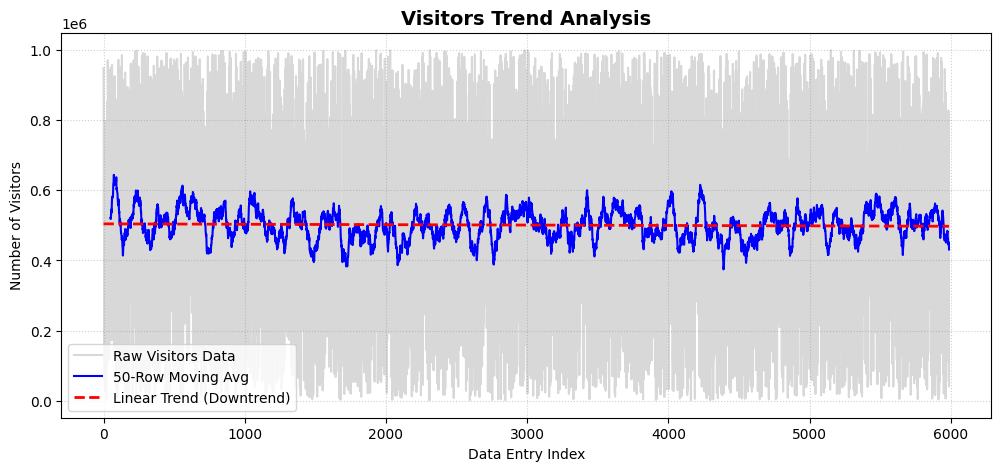

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df.index, df['Visitors'], alpha=0.3, color='gray', label='Raw Visitors Data')
plt.plot(df.index, df['Visitors_MA'], color='blue', linewidth=1.5, label=f'{window_size}-Row Moving Avg')
plt.plot(df.index, trend_line_visitors, color='red', linestyle='--', linewidth=2,
         label=f"Linear Trend ({'Uptrend' if slope_v > 0 else 'Downtrend'})")

plt.title('Visitors Trend Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Data Entry Index')
plt.ylabel('Number of Visitors')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

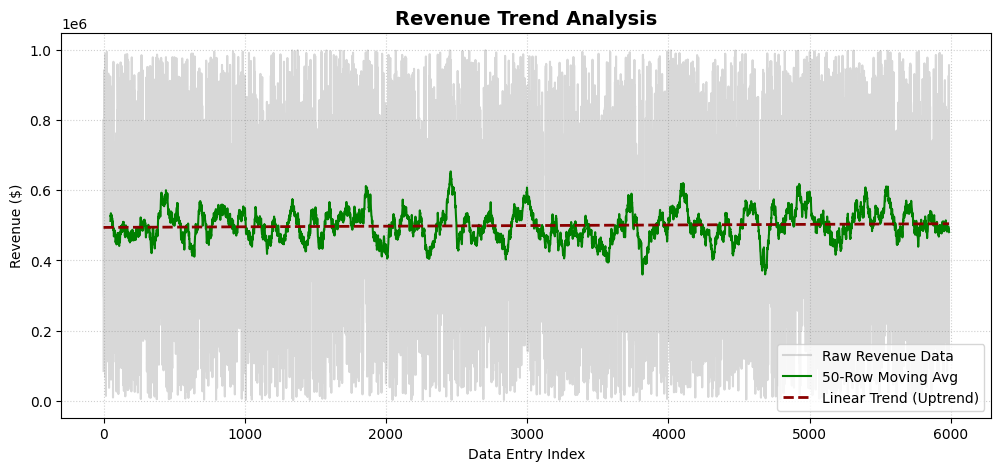

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df.index, df['Revenue'], alpha=0.3, color='gray', label='Raw Revenue Data')
plt.plot(df.index, df['Revenue_MA'], color='green', linewidth=1.5, label=f'{window_size}-Row Moving Avg')
plt.plot(df.index, trend_line_revenue, color='darkred', linestyle='--', linewidth=2,
         label=f"Linear Trend ({'Uptrend' if slope_r > 0 else 'Downtrend'})")

plt.title('Revenue Trend Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Data Entry Index')
plt.ylabel('Revenue ($)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()